# RL training for LLM agents — 2. From our trainer to verl

### Rebuilding the notebook 1 trainer from verl's pieces, one swap at a time

| # | Notebook | What it builds | Sections |
|---|---|---|---|
| 1 | [GRPO from scratch](1_grpo_from_scratch.ipynb) | an RL trainer in plain PyTorch, switched to verl's algorithm functions once they're checked against ours | §0–§2.2 |
| 2 | [From our trainer to verl](2_from_trainer_to_verl.ipynb) | a real inference engine (vLLM) and weight sync; then the same trainer, rebuilt from verl's pieces: `DataProto`, Ray actors, worker groups; then plain verl | §2.3–§2.6, §3, §5–§6 |
| 3 | [Training real agents](3_training_real_agents.ipynb) | multi-turn tool use, recording a real agent at the HTTP boundary, Agent Lightning, and verl + Agent Lightning end to end | §7–§10 |
| 4 | [Rewards: exact checks and LLM judges](4_rewards_and_judges.ipynb) | what a reward measures, and an LLM judge next to an exact check | own numbering |
| 5 | [Calc-X end to end](5_calc_x_end_to_end.ipynb) | one training step driven by hand through Agent Lightning, then a real training run | own numbering |

Notebooks 1–3 share one set of section numbers, so a reference like "§1.5" or "§8.1" always points to the same place, whichever notebook it appears in. Each notebook runs on its own: code from earlier notebooks is imported from `tutorial/lib/`, where it is copied verbatim.

**Where we are.** [Notebook 1](1_grpo_from_scratch.ipynb) built a complete GRPO trainer in plain PyTorch, using verl's advantage and loss functions once it had checked them against its own (§2.2). Batching made the update fast, so generation (`hf_generate`) is now most of each step. And everything runs in **one process**: one policy, one Python loop. That's fine for a 0.5B model on one GPU, and impossible for a 70B model on 64 GPUs.

**In this notebook** we first hand generation to a real inference engine, then replace our pieces with verl's, one at a time, and check after every swap that nothing changed except *whose* code runs:

| § | We write | Then replace it with | The problem that forces the swap |
|---|---|---|---|
| 2.3–2.6 | `hf_generate`: the training model generates | **vLLM**, with weight sync after every update | generation is most of each step |
| 3 | a dict of padded tensors | verl `DataProto` | a batch needs to travel between processes |
| 5 | one process doing everything | **Ray** actors: a rollout engine and a trainer | they need different resources and lifetimes |
| 6 | our own `WorkerGroup` (split → call → gather) | verl `RayWorkerGroup` + `@register(Dispatch...)` | one actor per GPU, N GPUs |
| 6.3 | | **plain verl**, on our arithmetic task | everything above, wired together |

**What we need to know already.** Notebook 1, or at least §1.3–§2.2: log-probs, GRPO advantages, PPO-clip, the batch layout, `rl_step`, and verl's `core_algos`. Its code is imported here from `tutorial/lib/rl_core.py`.

**Hardware and time.** One GPU with about 80 GB, and about 7 minutes on an H100, most of it in §2.5 and §6.3.

## 0. Setup

The same setup as notebook 1, plus notebook 1's trainer, imported from `tutorial/lib/rl_core.py`.

In [ ]:
import gc
import json
import os
import random
import re
import socket
import subprocess
import sys
import threading
import time
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "examples" / "calc_x").is_dir())
sys.path.insert(0, str(REPO / "tutorial/lib"))  # the series' shared code
from common import (CALC_X_DATA, CALC_X_MODEL, DEVICE, GENERATED, MODEL, SEED, SERVICES, SHM, VENV_BIN, WORK,  # noqa: E402
                    follow_log, gpu_free_gib, log_tail, setup, start_service, stop_service, wait_until_healthy)

setup()

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from rl_core import (EVAL, INSTRUCTION, LR, PAD_ID, STOP_IDS, TRAIN, chat_prompt_ids, compute_log_probs,  # noqa: E402
                     decode_tokens, evaluate, grpo_advantages, hf_generate, load_policy, make_optimizer, make_padded_batch,
                     ppo_clip_loss, ppo_update, print_step_metrics, rl_step, select_rows, tokenizer)
from arith_task import BOXED, make_problems, reward_fn, safe_eval  # noqa: E402
from transformers import AutoTokenizer, GenerationConfig  # noqa: E402
from vllm import LLM, SamplingParams, TokensPrompt  # noqa: E402
from rl_core import verl_ppo_loss  # noqa: E402
from verl.trainer.ppo.core_algos import compute_grpo_outcome_advantage  # noqa: E402

### 2.3 A real inference engine: vLLM

Generating the samples now takes far longer than learning from them. That's normal for RL on LLMs, and it's why every serious trainer hands generation to a dedicated **inference engine**. We'll use [vLLM](https://docs.vllm.ai).

**Why `model.generate` is slow.** It moves the whole batch forward together, one token per step, so three things go to waste:

* **Finished rows sit idle.** A response that stops after 50 tokens keeps its slot until the longest response in the batch finishes.
* **Memory is reserved up front.** Each row's key/value cache (the attention state for the tokens so far) is allocated as one block, big enough for the longest possible response, even if the row stops early. That caps how many rows fit on the GPU at once.
* **Python overhead every step.** Each new token launches hundreds of small GPU kernels from Python.

**What vLLM does instead:**

* **Continuous batching:** as soon as one sequence finishes, a waiting one takes its slot, so the GPU always works on a full batch.
* **PagedAttention:** the key/value cache is stored in small fixed-size blocks, handed out as a sequence grows, like pages of virtual memory. Nothing is reserved for tokens that never get written, so far more sequences fit at once.
* **CUDA graphs:** the GPU work for one decoding step is recorded once and replayed, skipping the per-step launch overhead.

```
static batching (model.generate)          continuous batching (vLLM)
slot 0:  A A A A A A A A                  slot 0:  A A A A A A A A
slot 1:  B B B · · · · ·  ← idle          slot 1:  B B B D D D D D  ← D starts as soon as B ends
slot 2:  C C C C C · · ·  ← idle          slot 2:  C C C C C E E E
```

Two things change the moment generation leaves the training model:

1. **There are now two copies of the weights.** After every update, the trainer must push its new weights into vLLM. Otherwise the next samples come from an old version of the policy, and the training math (which assumes the samples came from the current policy) quietly stops being true.
2. **vLLM has its own sampling defaults**, and they're not the ones we want.

We start from the original model: notebook 1's `load_policy` (with gradient checkpointing) and `make_optimizer`. vLLM then runs in this process (it starts its engine in a child process), on the same GPU, with 30% of GPU memory for its own copy of the weights and its key/value cache.

In [87]:
policy = load_policy()  # the original weights, with gradient checkpointing
optimizer = make_optimizer(policy, LR)

llm = LLM(model=MODEL, gpu_memory_utilization=0.3, max_model_len=4096, seed=SEED)
print("vLLM's default sampling params for this model:", llm.get_default_sampling_params())

WARNING 11-06 15:00:10 [config.py:70] Support for Transformers v4 is deprecated. The Transformers v4 codepath will become unmaintained in vLLM v0.22.0 and will be removed in vLLM v0.24.0. Please upgrade to Transformers v5: pip install --upgrade transformers
WARNING 11-06 15:00:15 [system_utils.py:157] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshooting.html#python-multiprocessing for more information. Reasons: CUDA is initialized
WARNING 11-06 15:00:18 [config.py:70] Support for Transformers v4 is deprecated. The Transformers v4 codepath will become unmaintained in vLLM v0.22.0 and will be removed in vLLM v0.24.0. Please upgrade to Transformers v5: pip install --upgrade transformers


Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  8.16it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  8.14it/s]
(EngineCore pid=330277) 
(EngineCore pid=330277) 2026-11-06 15:00:26,834 - INFO - autotuner.py:615 - flashinfer.jit: [Autotuner]: Autotuning process starts ...
(EngineCore pid=330277) 2026-11-06 15:00:26,841 - INFO - autotuner.py:634 - flashinfer.jit: [Autotuner]: Autotuning process ends
Capturing CUDA graphs (mixed prefill-decode, PIECEWISE): 100%|██████████| 51/51 [00:01<00:00, 48.51it/s]
Capturing CUDA graphs (decode, FULL): 100%|██████████| 51/51 [00:00<00:00, 67.72it/s]


WARNING 11-06 15:00:30 [model.py:1509] Default vLLM sampling parameters have been overridden by the model's `generation_config.json`: `{'repetition_penalty': 1.1, 'temperature': 0.7, 'top_k': 20, 'top_p': 0.8}`. If this is not intended, please relaunch vLLM instance with `--generation-config vllm`.
vLLM's default sampling params for this model: SamplingParams(n=1, presence_penalty=0.0, frequency_penalty=0.0, repetition_penalty=1.1, temperature=0.7, top_p=0.8, top_k=20, min_p=0.0, seed=None, stop=[], stop_token_ids=[], bad_words=[], thinking_token_budget=None, include_stop_str_in_output=False, ignore_eos=False, max_tokens=16, min_tokens=0, logprobs=None, prompt_logprobs=None, skip_special_tokens=True, spaces_between_special_tokens=True, structured_outputs=None, extra_args=None)


#### Sampling settings

Those defaults come from the model's `generation_config`, the settings Qwen recommends for *chatting*:

In [88]:
generation_config = GenerationConfig.from_pretrained(MODEL).to_dict()
sampling_keys = ("temperature", "top_p", "top_k", "repetition_penalty")
print("model's own sampling defaults:", {key: value for key, value in generation_config.items() if key in sampling_keys})

model's own sampling defaults: {'temperature': 0.7, 'top_k': 20, 'top_p': 0.8, 'repetition_penalty': 1.1}


Each of these changes the distribution the tokens are sampled from:

* **`top_k=20`** keeps only the 20 most likely tokens and renormalises them; everything else can never be sampled.
* **`top_p=0.8`** keeps only the most likely tokens that together make up 80% of the probability.
* **`temperature=0.7`** sharpens the distribution: likely tokens become even more likely.
* **`repetition_penalty=1.05`** makes tokens that already appeared less likely.

That's great for chatting, and wrong for RL. Our training math is about π, the model's actual distribution: log π(response), and the ratio π_θ / π_old. If the samples come from a truncated, sharpened version of π, the unlikely tokens are never sampled, so the model never learns whether they were good or bad, and the samples look more typical of the model than its real ones are. Training still runs, but learns about a distribution the model doesn't have.

That's why `hf_generate_single` and `hf_generate` have always passed `temperature=1.0, top_p=1.0, top_k=0, repetition_penalty=1.0`: those settings switch every modification off, so the samples are true draws from π. With vLLM we have to do the same, explicitly. Here's what happens if we don't: the same prompt, sampled with vLLM's defaults and with RL settings, then scored by our trainer:

In [89]:
default_params = SamplingParams(n=8, max_tokens=128)  # vLLM's defaults: the trap
rl_params = SamplingParams(n=8, temperature=1.0, top_p=1.0, top_k=0, repetition_penalty=1.0, max_tokens=128, logprobs=0)

test_prompt = chat_prompt_ids(TRAIN[0]["question"])
default_out = llm.generate([TokensPrompt(prompt_token_ids=test_prompt)], default_params)
rl_out = llm.generate([TokensPrompt(prompt_token_ids=test_prompt)], rl_params)

def mean_token_log_prob(outputs):
    """Trainer's mean per-token log-prob of each sample (via a forward pass, not the engine's own log-probs)."""
    response_ids = [list(completion.token_ids) for request in outputs for completion in request.outputs]
    batch = make_padded_batch([test_prompt] * len(response_ids), response_ids)
    log_probs = compute_log_probs(policy, batch)
    mask = batch["response_mask"]
    return (log_probs * mask).sum(-1) / mask.sum(-1)

lp_default = mean_token_log_prob(default_out)
lp_rl = mean_token_log_prob(rl_out)
print(f"mean log π per token with model defaults: {lp_default.mean():.2f}")
print(f"mean log π per token with RL settings:    {lp_rl.mean():.2f}")
print(f"\nper token, default samples are {torch.exp(lp_default.mean() - lp_rl.mean()):.2f}× more likely under the policy")

Processed prompts: 100%|██████████| 8/8 [00:00<00:00, 39.45it/s, est. speed input: 2297.57 toks/s, output: 4792.93 toks/s]


(EngineCore pid=330277) WARNING 11-06 15:00:51 [jit_monitor.py:103] Triton kernel JIT compilation during inference: _compute_slot_mapping_kernel. This causes a latency spike; consider extending warmup to cover this shape/config.


Processed prompts: 100%|██████████| 8/8 [00:00<00:00, 25.12it/s, est. speed input: 1461.32 toks/s, output: 3224.86 toks/s]

mean log π per token with model defaults: -0.30
mean log π per token with RL settings:    -0.37

per token, default samples are 1.07× more likely under the policy


The default-sampled responses are made only of likely tokens: top-k and top-p threw the unlikely ones away before sampling. Per token, the difference looks small (1.1× in our run), but a response is about 150 tokens long, and the per-token factors multiply: e^(0.09 × 150) ≈ e^13.5, so a whole default-sampled response is hundreds of thousands of times more likely under the policy than a typical true sample. Always set the sampling parameters explicitly for RL. verl does the same: it overrides the generation config when it launches vLLM.

**`vllm_generate`, step by step.** It passes our neutral settings, plus `logprobs=0`: "also return the log-prob of each sampled token" (the number is how many *extra* top alternatives to return; 0 means none). vLLM's output is nested, and the function flattens it into the same sample dicts `hf_generate` produces:

```
request_outputs                      one per prompt
 └─ request_output.outputs           samples_per_prompt completions for that prompt
     ├─ completion.token_ids         the sampled response tokens
     └─ completion.logprobs          one dict per position: {sampled_token_id: Logprob(logprob=-0.03, ...)}
```

For each completion, we look up the sampled token in its position's dict to get its log-prob. Unlike `hf_generate`, we now get the engine's own log-probs for free, which is what lets `rl_step` report `logp_mismatch`. (vLLM computes them from the raw model scores, before temperature scaling, so they only match the sampling distribution at temperature 1. RL rollouts use temperature 1 anyway.)

The cell also times both generators on the same 64 samples:

In [90]:
def vllm_generate(llm, prompts: list[list[int]], samples_per_prompt: int, max_tokens: int = 256, temperature: float = 1.0) -> list[dict]:
    # logprobs=0: return the log-prob of each sampled token (and no alternatives)
    params = SamplingParams(n=samples_per_prompt, temperature=temperature, top_p=1.0, top_k=0, repetition_penalty=1.0, max_tokens=max_tokens, logprobs=0)
    token_prompts = [TokensPrompt(prompt_token_ids=prompt) for prompt in prompts]
    request_outputs = llm.generate(token_prompts, params, use_tqdm=False)
    samples = []
    for prompt, request_output in zip(prompts, request_outputs):
        for completion in request_output.outputs:  # samples_per_prompt completions per prompt
            response_ids = list(completion.token_ids)
            # completion.logprobs holds one {token_id: Logprob} dict per position; look up the token that was sampled
            log_probs = []
            for token_id, logprobs_at_position in zip(response_ids, completion.logprobs):
                log_probs.append(logprobs_at_position[token_id].logprob)
            samples.append({"prompt_ids": list(prompt), "response_ids": response_ids, "log_probs": log_probs})
    return samples


prompts = [chat_prompt_ids(problem["question"]) for problem in TRAIN[:8]]
generators = {"HF generate": lambda: hf_generate(policy, prompts, 8), "vLLM": lambda: vllm_generate(llm, prompts, 8)}
for name, generate in generators.items():
    start = time.time()
    generated = generate()
    print(f"{name:12} {len(generated)} samples in {time.time() - start:5.2f}s")
print("vLLM samples end with a stop token:", np.mean([sample["response_ids"][-1] in STOP_IDS for sample in generated]))

HF generate  64 samples in  6.86s
vLLM         64 samples in  0.52s
vLLM samples end with a stop token: 0.953125


In our run, vLLM produced the same 64 samples about 12× faster, and the gap grows with batch size: a real RL step generates thousands of samples.

Most vLLM samples (94% in our run) end with a stop token. The rest hit the 256-token limit (`max_tokens`) and were cut off mid-response. A cut-off response almost never contains a final `\boxed{}` answer, so it scores 0. That's a signal too: it teaches the model to finish within the budget.

### 2.4 Weight sync

The trainer updates its weights; vLLM needs those new weights before it generates the next batch. The simplest correct way takes two steps:

1. The trainer writes its weights to `/dev/shm` (a folder that lives in RAM, not on disk) in the Hugging Face checkpoint format, as bf16. vLLM computes in bf16 anyway, so it doesn't need the fp32 master weights. That's the **data plane**: the bulk of the bytes.
2. A tiny control message, `collective_rpc("reload_weights", ...)`, tells every vLLM worker to reload from that folder. That's the **control plane**: "new weights are ready, here's where".

Then we **reset vLLM's prefix cache**. vLLM remembers the key/value cache it computed for prompt beginnings it has already seen, and reuses it whenever a new prompt starts with the same tokens. Every prompt here begins with the same system prompt and chat-template tokens, so that's a big saving. But those cached values were computed with the *old* weights. After a weight update they're wrong, and vLLM would still reuse them, because the tokens match. Resetting the cache forces a recompute.

Two details in `save_for_inference`: Qwen2.5-0.5B **ties** its output layer to its input embedding (`tie_word_embeddings`, one matrix used for both), so we drop the duplicate `lm_head.weight` and vLLM ties them itself. And the reload prints a "RotaryEmbedding: Failed to load weights" warning. It's harmless: the rotary position embedding has no trained weights to load.

verl does the same thing faster. It sends bf16 tensors straight from the trainer's GPU memory to vLLM over CUDA IPC (same GPU) or NCCL (different GPUs), in buckets, with no copy through host memory. The structure is identical: a control call says *"new weights are coming"*, then a data channel moves them.

Our fresh policy and vLLM both loaded the original checkpoint, so they already agree; we sync once anyway, to check it works. Then we measure held-out accuracy with the same `evaluate` as before, now with vLLM generating greedily (temperature 0).

In [91]:
import safetensors.torch


def save_for_inference(model, path: Path = SHM / "policy") -> str:
    path.mkdir(parents=True, exist_ok=True)
    state = {}
    for name, tensor in model.state_dict().items():
        state[name] = tensor.detach().to(torch.bfloat16).cpu().contiguous()  # a bf16 copy on the CPU, ready to write
    if model.config.tie_word_embeddings:
        state.pop("lm_head.weight", None)  # same tensor as the embedding; vLLM ties them itself
    safetensors.torch.save_file(state, str(path / "model.safetensors"))
    return str(path)


def push_weights(model, llm) -> None:
    weights_path = save_for_inference(model)                                     # 1. data plane: write the weights to RAM
    llm.collective_rpc("reload_weights", kwargs={"weights_path": weights_path})  # 2. control plane: tell vLLM to load them
    llm.reset_prefix_cache()  # cached KV values were computed with the old weights


t0 = time.time()
push_weights(policy, llm)
print(f"weights pushed in {time.time() - t0:.1f}s")

acc_before = evaluate(lambda prompts, samples_per_prompt: vllm_generate(llm, prompts, samples_per_prompt, temperature=0.0))
print(f"greedy accuracy on {len(EVAL)} held-out problems before RL: {acc_before:.3f}")

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.16it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.16it/s]
(EngineCore pid=330277) 


(EngineCore pid=330277) WARNING 11-06 15:01:05 [layerwise.py:253] RotaryEmbedding: Failed to load weights
weights pushed in 1.1s
greedy accuracy on 200 held-out problems before RL: 0.740


(This is a little different from the HF number at the start: vLLM and HF use different GPU kernels, and greedy decoding can take a different path at the first token where two candidates are nearly tied.)

### 2.5 Train, with vLLM generating

The same `rl_step`, now with `vllm_generate`, and with `push_weights` after every update. Each step samples 16 questions × 8 samples = 128 rows; with `mini_batch_size=64`, that's two optimizer steps per training step, as in §1.7.

How to read a step line:

| Field | Meaning | What to look for |
|---|---|---|
| `reward` | mean reward of this step's 128 samples | should trend up, noisily (16 questions is a small batch) |
| `format` | fraction of responses with a `\boxed{}` number at all, right or wrong | separates "learned the format" from "learned the arithmetic" |
| `len` | mean response length in tokens | how the model's behaviour is changing |
| `grad_norm` | size of the gradient before clipping | a sudden spike means an unusual batch |
| `logp mismatch` | mean \|log π_trainer − log π_vLLM\| over trained tokens | small and flat. vLLM and the trainer use different kernels, so below about 0.01 is normal. If we deleted the `push_weights` line it would creep up, as the trainer drifts away from what vLLM serves |
| `gen`, `old_log_prob`, `update`, `sync` | seconds spent in each phase | generation is now a small part of the step |

In [92]:
step_rng = random.Random(SEED)
vllm_history = []
for step in range(20):
    metrics, batch, samples = rl_step(policy, optimizer, lambda prompts, samples_per_prompt: vllm_generate(llm, prompts, samples_per_prompt), step_rng.sample(TRAIN, 16), samples_per_prompt=8)
    start = time.time()
    push_weights(policy, llm)
    metrics["time/sync"] = time.time() - start
    vllm_history.append(metrics)
    print_step_metrics(step, metrics)

acc_after = evaluate(lambda prompts, samples_per_prompt: vllm_generate(llm, prompts, samples_per_prompt, temperature=0.0))
print(f"\ngreedy accuracy on held-out problems: {acc_before:.3f} before -> {acc_after:.3f} after {len(vllm_history)} steps")

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.19it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.18it/s]
(EngineCore pid=330277) 


(EngineCore pid=330277) WARNING 11-06 15:03:13 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step  0 | reward 0.609 | format 0.83 | len 148.3 | grad_norm 2.267 | logp mismatch 0.0091 | gen  0.7s old_log_prob  0.3s update  2.4s sync  1.0s


Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.10it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.10it/s]
(EngineCore pid=330277) 


(EngineCore pid=330277) WARNING 11-06 15:03:18 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step  1 | reward 0.539 | format 0.77 | len 161.2 | grad_norm 2.338 | logp mismatch 0.0090 | gen  0.7s old_log_prob  0.3s update  2.6s sync  1.0s


Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.19it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.18it/s]
(EngineCore pid=330277) 


(EngineCore pid=330277) WARNING 11-06 15:03:22 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step  2 | reward 0.586 | format 0.91 | len 152.8 | grad_norm 2.021 | logp mismatch 0.0079 | gen  0.7s old_log_prob  0.3s update  2.3s sync  1.0s


... (30 outputs left out)

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.16it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.16it/s]
(EngineCore pid=330277) 


(EngineCore pid=330277) WARNING 11-06 15:04:32 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step 18 | reward 0.930 | format 1.00 | len 143.1 | grad_norm 0.654 | logp mismatch 0.0039 | gen  0.7s old_log_prob  0.3s update  2.6s sync  1.1s


Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.15it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.14it/s]
(EngineCore pid=330277) 


(EngineCore pid=330277) WARNING 11-06 15:04:37 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step 19 | reward 0.828 | format 0.98 | len 147.3 | grad_norm 1.659 | logp mismatch 0.0045 | gen  0.7s old_log_prob  0.3s update  2.3s sync  1.1s

greedy accuracy on held-out problems: 0.740 before -> 0.915 after 20 steps


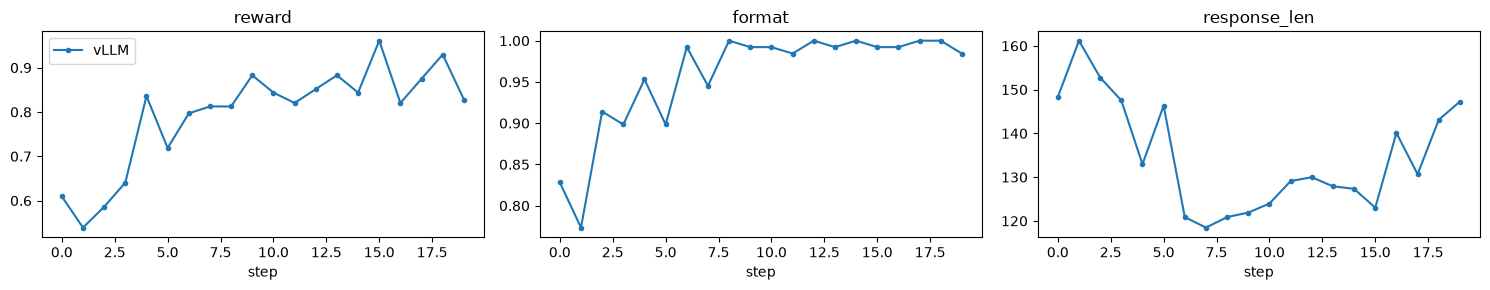

In [93]:
def plot_histories(histories: dict[str, list[dict]], keys=("reward", "response_len")) -> None:
    fig, axes = plt.subplots(1, len(keys), figsize=(5 * len(keys), 3))
    for ax, key in zip(np.atleast_1d(axes), keys):
        for name, history in histories.items():
            ax.plot([metrics[key] for metrics in history], marker="o", ms=3, label=name)
        ax.set_title(key)
        ax.set_xlabel("step")
    np.atleast_1d(axes)[0].legend()
    plt.tight_layout()
    plt.show()


plot_histories({"vLLM": vllm_history}, keys=("reward", "format", "response_len"))

Each step now takes about 4 seconds instead of 10 or more, and generation is the smallest part of it: about 0.7 s for 128 samples.

Reward and format rise together at first. In our runs, the format went from about 85% to 99% or 100% within about a dozen steps: almost every response now ends with a `\boxed{}`. A response without one always scores 0, so that alone accounts for much of the early rise in reward. After that the format has nowhere left to go, but the reward keeps improving, noisily, and greedy held-out accuracy went from 0.740 to somewhere between 0.80 and 0.93 (it varies from run to run, as §1.7 explained), so the model is getting more of the arithmetic right too. Responses also got shorter, from about 150 tokens to between 100 and 130.

The first thing RL teaches is usually whatever the reward checks most directly, here the format. So a big early jump in reward is rarely a jump in ability, and it's worth tracking the format separately, as we did here.

### 2.6 The trainer and vLLM don't quite agree

`logp_mismatch` is an average, and averages hide things. In the last batch, let's look at the distribution of the per-token difference between the trainer's log-probs (`old_log_probs`, recomputed by our policy) and the log-probs vLLM reported when it sampled the same tokens. In PPO terms, exp(difference) is the ratio ρ that the very first update would see if we used vLLM's numbers as π_old: it should be exactly 1.

18850 trained tokens: mean |Δ| = 0.0045, 99th percentile |Δ| = 0.106, max |Δ| = 0.671
implied ratio exp(Δ) ranges over [0.511, 1.455], before any update


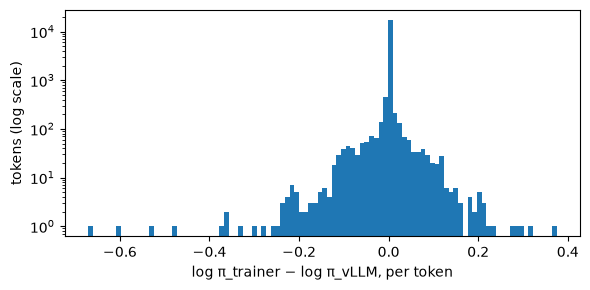

In [94]:
trained = batch["response_mask"].bool()
engine_log_probs = torch.zeros_like(batch["old_log_probs"])
for row, sample in enumerate(samples):
    engine_log_probs[row, : len(sample["log_probs"])] = torch.tensor(sample["log_probs"])
diff = (batch["old_log_probs"] - engine_log_probs)[trained]  # log π_trainer − log π_vLLM, one entry per trained token
print(f"{diff.numel()} trained tokens: mean |Δ| = {diff.abs().mean():.4f}, 99th percentile |Δ| = {diff.abs().quantile(0.99):.3f}, max |Δ| = {diff.abs().max():.3f}")
print(f"implied ratio exp(Δ) ranges over [{diff.exp().min():.3f}, {diff.exp().max():.3f}], before any update")

plt.figure(figsize=(6, 3))
plt.hist(diff.numpy(), bins=100, log=True)
plt.xlabel("log π_trainer − log π_vLLM, per token")
plt.ylabel("tokens (log scale)")
plt.tight_layout()
plt.show()

Most tokens agree almost exactly, so the mean difference is tiny (about 0.005), but the distribution has a long tail: one token in a hundred is off by about 0.1 or more, and the worst by about 0.5.

Why does that matter? Suppose we had used vLLM's log-probs as π_old in the PPO ratio. Take a token where the trainer says log π = −2.00 and vLLM said −2.26. Before any update, the ratio would be e^(−2.00 − (−2.26)) = e^0.26 ≈ 1.30. That's already past the clip limit of 1.28, so if the token had a positive advantage, its gradient would be zero: the clip would block an update that never happened, purely because two programs compute the same number slightly differently.

That's why `rl_step` recomputes `old_log_probs` with the trainer instead of trusting vLLM's numbers: the PPO ratio must compare like with like, so that ρ = 1 exactly before the first update. verl does the same (its `compute_log_prob` step), keeps vLLM's numbers as `rollout_log_probs`, and can use the gap for importance-sampling corrections (`algorithm.rollout_correction`). At scale, this train/inference mismatch is one of the main sources of RL instability, which is why verl can log it every step (`rollout_corr/kl`, which we'll see in notebook 3).

## 3. Swap 2: the batch becomes a `DataProto`

So far, a batch has been a dict of tensors, plus some side lists kept in separate variables: which group each sample belongs to, the correct answers. That works while everything happens in one place. But from §5 on, the batch has to be **sent to other processes** and **split across workers**, and every split must cut the tensors *and* the side lists at exactly the same rows. Do that by hand in a few places and, sooner or later, row 37's reward ends up attached to row 38's response, with no error anywhere.

verl's container for this is `DataProto`, which keeps everything about a row together:

* `.batch`: a `TensorDict`, a dict of tensors that all share the first (row) dimension, so they're always sliced together;
* `.non_tensor_batch`: numpy object arrays with the same first dimension (group ids, strings, answers);
* `.meta_info`: a plain dict for values that apply to the whole batch (temperature, step, …).

Because §2.1 used verl's key names, the swap is one call: `DataProto.from_dict(tensors=make_padded_batch(...), ...)`. And because `select_rows()` also accepts a `TensorDict`, every function from §2.1 works unchanged on `batch.batch`. Here are the operations the rest of the notebook relies on:

In [ ]:
from verl import DataProto

proto = DataProto.from_dict(
    tensors=make_padded_batch([sample["prompt_ids"] for sample in samples], [sample["response_ids"] for sample in samples]),
    non_tensors={"uid": np.array([i // 8 for i in range(len(samples))], dtype=object)},  # uid = group: sample i answers question i // 8
    meta_info={"temperature": 1.0},
)
print(f"{len(proto)} rows; tensors: {list(proto.batch.keys())}; non-tensors: {list(proto.non_tensor_batch)}; meta: {proto.meta_info}")

print("index with a list:     ", len(proto[[0, 5, 9]]), "rows, uids", proto[[0, 5, 9]].non_tensor_batch["uid"].tolist())
halves = proto.chunk(2)
print("chunk(2):              ", [len(half) for half in halves], "-> concat:", len(DataProto.concat(halves)))
extra = DataProto.from_dict(tensors={"old_log_probs": torch.zeros_like(proto.batch["responses"], dtype=torch.float32)})
print("union adds a column:   ", "old_log_probs" in proto.union(extra).batch.keys())
print("repeat(2, interleave): ", proto[[0, 1]].repeat(2, interleave=True).non_tensor_batch["uid"].tolist())
print("works with §2.1 helpers: ", compute_log_probs(policy, proto.batch).shape)

Reading the output line by line:

* **Indexing with a list** picks rows 0, 5 and 9 from every tensor and every side array at once. With 8 samples per question, rows 0 and 5 belong to question 0 and row 9 to question 1, hence uids `[0, 0, 1]`.
* **`chunk(2)`** splits the 128 rows into two halves of 64, and **`concat`** joins them back. These are the two operations a worker group (§6) is built on: split the batch into one piece per worker, run, and concatenate the results.
* **`union`** adds new columns to a batch. It's how verl attaches results as the batch moves through the pipeline: `old_log_probs` from the actor, `ref_log_prob` from the reference model, `values` from the critic, then `advantages`.
* **`repeat(2, interleave=True)`** copies every row, keeping the copies next to each other: rows `[r0, r1]` become `[r0, r0, r1, r1]`. (Rows 0 and 1 both belong to question 0, which is why all four uids are 0.) verl uses exactly this to turn one prompt per question into *n* copies before generation, and the interleaving is what makes the samples prompt-major, as in §1.6.
* **`compute_log_probs`** from §2.1 runs unchanged on `proto.batch`.

**The training step with the batch as a `DataProto`.** Notebook 1's `rl_step` already uses verl's advantage and loss functions (`compute_grpo_outcome_advantage` and the vanilla PPO-clip loss, wrapped in `verl_ppo_loss`). What changes now is the container: the batch becomes a `DataProto`, with the group ids and answers travelling alongside the tensors. Three small functions do the work, and each one fills in some of the keys verl's trainer works with:

| Function | Adds to the batch | verl's trainer does this in |
|---|---|---|
| `build_batch` | `prompts`, `responses`, masks, `uid`, `answer`, `token_level_rewards`, `rollout_log_probs` | the rollout and reward steps |
| (`compute_log_probs`) | `old_log_probs` | `compute_log_prob` |
| `add_advantages` | `advantages` | `compute_advantage` |
| `compute_batch_metrics` | nothing: reads the batch and reports reward, length and `logp_mismatch` | its metric logging |

`token_level_rewards` is verl's per-token reward layout from notebook 1: each response's reward on its last real token. We'll reuse `build_batch` in every remaining stage.

In [ ]:
def build_batch(samples: list[dict], answers: list[int], uids: list) -> DataProto:
    """Score samples and lay them out the way verl's trainer expects."""
    rewards = torch.tensor([reward_fn(decode_tokens(sample["response_ids"]), answer) for sample, answer in zip(samples, answers)])
    batch = DataProto.from_dict(
        tensors=make_padded_batch([sample["prompt_ids"] for sample in samples], [sample["response_ids"] for sample in samples]),
        non_tensors={"uid": np.array(uids, dtype=object), "answer": np.array(answers, dtype=object)},
        meta_info={"temperature": 1.0},
    )
    mask = batch.batch["response_mask"]

    # Each response's reward goes on its last token (verl's token_level_rewards layout)
    last_token = mask.sum(-1).clamp(min=1) - 1
    token_level_rewards = torch.zeros(mask.shape)
    token_level_rewards[torch.arange(len(batch)), last_token] = rewards
    batch.batch["token_level_rewards"] = token_level_rewards

    # The inference engine's log-probs, padded like the responses (for the logp_mismatch metric)
    rollout_log_probs = torch.zeros(mask.shape)
    for row, sample in enumerate(samples):
        if sample["log_probs"] is not None:
            rollout_log_probs[row, : len(sample["log_probs"])] = torch.tensor(sample["log_probs"])
    batch.batch["rollout_log_probs"] = rollout_log_probs
    return batch


def add_advantages(batch: DataProto) -> DataProto:
    advantages, _ = compute_grpo_outcome_advantage(
        token_level_rewards=batch.batch["token_level_rewards"], response_mask=batch.batch["response_mask"], index=batch.non_tensor_batch["uid"],
    )
    batch.batch["advantages"] = advantages
    return batch


def compute_batch_metrics(batch: DataProto) -> dict:
    trained = batch.batch["response_mask"].bool()
    metrics = {"reward": batch.batch["token_level_rewards"].sum(-1).mean().item(), "response_len": trained.sum(-1).float().mean().item()}
    if "old_log_probs" in batch.batch.keys():
        metrics["logp_mismatch"] = (batch.batch["old_log_probs"] - batch.batch["rollout_log_probs"])[trained].abs().mean().item()
    return metrics


def rl_step_verl(problems, samples_per_prompt: int = 8) -> tuple[dict, DataProto]:
    timing = {}
    start = time.time()
    samples = vllm_generate(llm, [chat_prompt_ids(problem["question"]) for problem in problems], samples_per_prompt)
    timing["gen"] = time.time() - start

    group_ids = [i // samples_per_prompt for i in range(len(samples))]  # sample i answers problem i // samples_per_prompt
    batch = build_batch(samples, [problems[group]["answer"] for group in group_ids], group_ids)

    start = time.time()
    batch.batch["old_log_probs"] = compute_log_probs(policy, batch.batch)
    timing["old_log_prob"] = time.time() - start

    add_advantages(batch)

    start = time.time()
    stats = ppo_update(
        policy, optimizer, batch.batch,
        old_log_probs=batch.batch["old_log_probs"], advantages=batch.batch["advantages"], loss_fn=verl_ppo_loss,
    )
    timing["update"] = time.time() - start

    start = time.time()
    push_weights(policy, llm)
    timing["sync"] = time.time() - start
    return {**compute_batch_metrics(batch), **stats, **{f"time/{name}": seconds for name, seconds in timing.items()}}, batch


verl_fn_history = []
for step in range(5):
    metrics, last_batch = rl_step_verl(step_rng.sample(TRAIN, 16))
    verl_fn_history.append(metrics)
    print_step_metrics(step + 1, metrics)

Same numbers, same behaviour; we've only changed the container. That's what lets the batch travel: everything about a row now moves with it.

Everything still runs in **one process**. That's fine on one GPU for a 0.5B model, and impossible for a 70B model on 64 GPUs.

## 5. Swap 4: separate processes with Ray

Right now one Python process owns the policy, the optimizer, the vLLM engine and the training loop. At scale these become different *roles* with different resources: the rollout engine wants many GPUs with lots of KV-cache memory, the trainer wants GPUs sharded with FSDP, and a reward model might want its own. [Ray](https://docs.ray.io) lets one driver script start Python objects in other processes, on any machine, and call their methods as if they were local:

* a **task** is a remote function call: `f.remote(x)` returns a future, `ray.get(future)` waits for the value;
* an **actor** is a remote object: a dedicated process that keeps state (a model, an optimizer) between calls;
* the **object store** passes arguments and results between processes without copying them through the driver more than needed.

First, free the GPU: the in-process vLLM engine and the policy go away, and Ray actors take over.

In [ ]:
llm.llm_engine.engine_core.shutdown()
del llm, policy, optimizer
gc.collect()
torch.cuda.empty_cache()
print(f"GPU free: {gpu_free_gib():.0f} GiB")

import ray

ray.init(num_cpus=32, num_gpus=1, include_dashboard=False, runtime_env={"env_vars": {k: os.environ[k] for k in ("PYTHONPATH", "TOKENIZERS_PARALLELISM", "VLLM_LOGGING_LEVEL")}})


@ray.remote
def square(x):
    return x * x, os.getpid()


print("driver pid:", os.getpid(), "| tasks ran in:", ray.get([square.remote(i) for i in range(4)]))
print("cluster resources:", ray.cluster_resources())

`square.remote(i)` doesn't run `square`; it schedules it and immediately returns a **future** (an `ObjectRef`), a ticket for a result that doesn't exist yet. `ray.get(...)` waits for the results. The output shows that each call ran in a different process (four different pids, none of them the driver's), and that the results come back in the order we asked for them, whichever finished first.

`cluster_resources` is what Ray can hand out: 32 CPUs and 1 GPU here. Every task and actor says how much of these it needs, and Ray places it somewhere that has room.

Now the two roles become **actors**: long-lived processes that keep their state (a vLLM engine; a policy and its optimizer) between calls. The code inside them is the code we already wrote: `vllm_generate`, `compute_log_probs`, `ppo_update`, `save_for_inference`. Ray ships these functions to the worker processes.

```
driver process (this notebook: no GPU work)
  │  generate.remote(prompts)               ┌────────────────────────────────┐
  ├────────────────────────────────────────►│ RolloutWorker   (vLLM)         │  ─┐
  │  compute_log_probs / update.remote(batch)├────────────────────────────────┤   ├─ one GPU
  ├────────────────────────────────────────►│ TrainerWorker  (policy + Adam)  │  ─┘
  │  ◄── samples, log-probs, metrics         └────────────────────────────────┘
  │       (through Ray's object store)
weights: TrainerWorker ──writes──► /dev/shm/…/model.safetensors ──reads──► RolloutWorker
         (only the path travels through Ray)
```

`num_gpus=0.3` and `num_gpus=0.6` are **scheduling labels**, not memory limits: they let Ray place both actors on one GPU (0.3 + 0.6 ≤ 1). Memory is still governed by vLLM's `gpu_memory_utilization` and by what the trainer allocates. Putting rollout and training on the same GPUs is verl's **colocated** (hybrid engine) layout. The alternative, separate GPU pools for each role, is what verl calls *disaggregated*, and is what we'd need for asynchronous training.

In [ ]:
@ray.remote(num_gpus=0.3)
class RolloutWorker:
    def __init__(self, model: str, gpu_memory_utilization: float = 0.3):
        self.llm = LLM(model=model, gpu_memory_utilization=gpu_memory_utilization, max_model_len=4096, seed=SEED)

    def generate(self, prompts, samples_per_prompt, max_tokens=256, temperature=1.0):
        return vllm_generate(self.llm, prompts, samples_per_prompt, max_tokens, temperature)

    def load_weights(self, path: str) -> None:
        self.llm.collective_rpc("reload_weights", kwargs={"weights_path": path})
        self.llm.reset_prefix_cache()

    def shutdown(self) -> None:
        self.llm.llm_engine.engine_core.shutdown()

    def info(self) -> dict:
        return {"role": "rollout", "pid": os.getpid(), "CUDA_VISIBLE_DEVICES": os.environ.get("CUDA_VISIBLE_DEVICES")}


@ray.remote(num_gpus=0.6)
class TrainerWorker:
    def __init__(self, model: str, lr: float):
        self.policy = load_policy(model)
        self.optimizer = make_optimizer(self.policy, lr)

    def compute_log_probs(self, batch: DataProto) -> torch.Tensor:
        return compute_log_probs(self.policy, batch.batch)

    def update(self, batch: DataProto) -> dict:
        return ppo_update(
            self.policy, self.optimizer, batch.batch,
            old_log_probs=batch.batch["old_log_probs"], advantages=batch.batch["advantages"], loss_fn=verl_ppo_loss,
        )

    def save_weights(self) -> str:
        return save_for_inference(self.policy)

    def info(self) -> dict:
        return {"role": "trainer", "pid": os.getpid(), "CUDA_VISIBLE_DEVICES": os.environ.get("CUDA_VISIBLE_DEVICES")}


rollout = RolloutWorker.remote(MODEL)
trainer = TrainerWorker.remote(MODEL, LR)
for info in ray.get([rollout.info.remote(), trainer.info.remote()]):
    print(info)
print("\nprocesses on the GPU:\n" + subprocess.run(["nvidia-smi", "--query-compute-apps=pid,used_memory", "--format=csv"], capture_output=True, text=True).stdout)

The driver loop is the §3 loop with `.remote(...)` and `ray.get(...)` added. Following one step through the processes:

| Step | Runs in | What crosses a process boundary |
|---|---|---|
| generate | `RolloutWorker` | prompts in; sample dicts (tokens + vLLM log-probs) out |
| `build_batch`, rewards | driver | (nothing: cheap CPU work) |
| old log-probs | `TrainerWorker` | the `DataProto` in; a log-prob tensor out |
| advantages | driver | (nothing: cheap tensor maths) |
| update | `TrainerWorker` | the `DataProto` in; metrics out |
| weight sync | both | a file path, through Ray; the weights themselves, through `/dev/shm` |

The driver never touches the GPU: it builds batches and computes advantages, exactly like verl's `RayPPOTrainer.fit()`. And the control/data split from §2.4 is now visible: the **path** travels through Ray, the **weights** through shared memory.

These actors start from the base model (the §3 policy is gone), so the reward starts lower again.

In [ ]:
def ray_rl_step(problems, samples_per_prompt: int = 8) -> tuple[dict, DataProto, list[dict]]:
    timing = {}
    start = time.time()
    samples = ray.get(rollout.generate.remote([chat_prompt_ids(problem["question"]) for problem in problems], samples_per_prompt))
    timing["gen"] = time.time() - start

    group_ids = [i // samples_per_prompt for i in range(len(samples))]  # sample i answers problem i // samples_per_prompt
    batch = build_batch(samples, [problems[group]["answer"] for group in group_ids], group_ids)

    start = time.time()
    batch.batch["old_log_probs"] = ray.get(trainer.compute_log_probs.remote(batch))
    timing["old_log_prob"] = time.time() - start

    add_advantages(batch)

    start = time.time()
    stats = ray.get(trainer.update.remote(batch))
    timing["update"] = time.time() - start

    start = time.time()
    weights_path = ray.get(trainer.save_weights.remote())
    ray.get(rollout.load_weights.remote(weights_path))
    timing["sync"] = time.time() - start
    return {**compute_batch_metrics(batch), **stats, **{f"time/{name}": seconds for name, seconds in timing.items()}}, batch, samples


ray_history = []
for step in range(10):
    metrics, last_batch, last_samples = ray_rl_step(step_rng.sample(TRAIN, 16))
    ray_history.append(metrics)
    print_step_metrics(step, metrics)
plot_histories({"§3 one process": verl_fn_history, "§5 Ray actors": ray_history})

What Ray bought us, even on one GPU: the roles are independent processes with their own lifetimes and resources, and the driver is a plain Python loop. The same code would place `RolloutWorker` and `TrainerWorker` on different machines if the cluster had them.

What it **didn't** buy yet: each role is a single process. A 70B policy doesn't fit on one GPU, and one vLLM engine can't serve thousands of samples quickly enough. Each role needs to become *N* processes working together.

## 6. Swap 5: many workers per role

### 6.1 Our own worker group

A model too big for one GPU, or more samples than one vLLM engine can generate in time, means each role must become *N* processes working together. A **worker group** is *N* actors of the same class, plus a rule for each method that says how to split the input and combine the output. Two rules cover most of verl:

```
one-to-all: init_process_group()               data-parallel: score(batch of 128 rows)

  driver ──same call──► worker 0                 rows   0–63  ──► worker 0 ──► 64 rewards ─┐
         ──same call──► worker 1                 rows 64–127  ──► worker 1 ──► 64 rewards ─┴─► concat: 128 rewards
         ◄── [result 0, result 1]
```

* **one-to-all**: send the same arguments to every worker and return all their results. Used for setup and housekeeping: `init_model`, `save_checkpoint`, …
* **data-parallel**: `chunk` the `DataProto` into *N* pieces, give one piece to each worker, and `concat` the results in order. Used for the real work: `compute_log_prob`, `update_actor`, …

On one GPU we can't run *N* GPU trainers meaningfully, so the workers here are CPU actors that **score** responses. It's a real job (verl runs reward computation in parallel workers too) and cheap enough to demonstrate the pattern.

**Two channels between workers.** Ray creates the processes and calls their methods: that's **control**. But workers training one model also need to exchange tensors directly with each other, many times per step, without going through the driver: that's **data**, and it's `torch.distributed`'s job. Before they can talk, the workers must find each other. Each gets a **rank** (its number, 0 to N−1) and the **world size** N, and they all connect to an agreed address (`MASTER_ADDR`, `MASTER_PORT`) to form a **process group**. Then they can run **collectives** such as `all_reduce`: every worker contributes a tensor, and every worker gets back the sum:

```
before all_reduce:   worker 0: [1.0]    worker 1: [2.0]
after all_reduce:    worker 0: [3.0]    worker 1: [3.0]
```

FSDP's all-gathers and gradient reductions are exactly such collectives, over NCCL between GPUs. Our CPU workers use `gloo`, the CPU backend.

In [ ]:
def free_port() -> int:
    with socket.socket() as sock:
        sock.bind(("127.0.0.1", 0))  # port 0: the OS picks a free one
        return sock.getsockname()[1]


@ray.remote(num_cpus=1)
class ScoreWorker:
    def __init__(self, rank: int, world_size: int, master_port: int):
        self.rank, self.world_size = rank, world_size
        os.environ.update(MASTER_ADDR="127.0.0.1", MASTER_PORT=str(master_port))
        self.tokenizer = AutoTokenizer.from_pretrained(MODEL)

    def init_process_group(self) -> int:
        torch.distributed.init_process_group("gloo", rank=self.rank, world_size=self.world_size)
        return self.rank

    def all_reduce(self, value: float) -> float:
        total = torch.tensor([value])
        torch.distributed.all_reduce(total)  # sum across all workers, in place, directly between the processes
        return total.item()

    def score(self, data: DataProto) -> DataProto:
        texts = self.tokenizer.batch_decode(data.batch["responses"], skip_special_tokens=True)
        rewards = torch.tensor([reward_fn(text, int(answer)) for text, answer in zip(texts, data.non_tensor_batch["answer"])])
        return DataProto.from_dict(tensors={"reward": rewards}, non_tensors={"scored_by": np.full(len(data), self.rank, dtype=object)})


class MyWorkerGroup:
    def __init__(self, workers):
        self.workers = workers

    def one_to_all(self, method: str, *args):
        """Call the same method, with the same arguments, on every worker."""
        return ray.get([getattr(worker, method).remote(*args) for worker in self.workers])

    def data_parallel(self, method: str, data: DataProto) -> DataProto:
        """Split the batch into one chunk per worker, run the chunks in parallel, and concatenate the results."""
        chunks = data.chunk(len(self.workers))
        results = ray.get([getattr(worker, method).remote(chunk) for worker, chunk in zip(self.workers, chunks)])
        return DataProto.concat(results)


port = free_port()
my_wg = MyWorkerGroup([ScoreWorker.remote(rank, 2, port) for rank in range(2)])
print("ranks joined:", my_wg.one_to_all("init_process_group"))
print("each worker contributes rank + 1; all_reduce returns the sum on every worker:",
      ray.get([worker.all_reduce.remote(float(rank + 1)) for rank, worker in enumerate(my_wg.workers)]))

scored = my_wg.data_parallel("score", last_batch)
reference = last_batch.batch["token_level_rewards"].sum(-1)
print(f"scored {len(scored)} rows; matches the driver's rewards: {torch.equal(scored.batch['reward'], reference)}")
print("rows per worker:", pd.Series(scored.non_tensor_batch["scored_by"]).value_counts().sort_index().to_dict())

Reading the output: both ranks joined the process group; each worker contributed `rank + 1` (1 and 2) and both got back 3, the sum; and the data-parallel `score` split the last batch's 128 rows into 64 per worker and reproduced the driver's rewards exactly. The `scored_by` column records which worker scored each row.

### 6.2 verl's `RayWorkerGroup`

verl packages exactly this pattern. We subclass `Worker`, and **decorate each method with its dispatch rule**. `RayWorkerGroup` then creates one actor per slot in a `RayResourcePool`, sets `RANK`, `WORLD_SIZE`, `MASTER_ADDR` and `MASTER_PORT` in each actor's environment, and gives the group a method of the same name that splits, calls and gathers for us:

| Our §6.1 code | verl |
|---|---|
| `my_wg.one_to_all("init_process_group")` | `@register(dispatch_mode=Dispatch.ONE_TO_ALL)` → `wg.init_process_group()` |
| `my_wg.data_parallel("score", batch)` | `@register(dispatch_mode=Dispatch.DP_COMPUTE_PROTO)` → `wg.score(batch)` |
| `rank`, `world_size`, `master_port` passed by hand | read from the environment verl sets: `self.rank`, `self.world_size` |
| `[ScoreWorker.remote(...) for rank in range(2)]` | `RayResourcePool(process_on_nodes=[2])` + `RayClassWithInitArgs` |

A resource pool reserves one Ray *placement-group bundle* per worker, and with `use_gpu=True` each bundle is **one whole GPU**. That's why the demonstration uses CPU workers (`use_gpu=False`): on one GPU, a GPU pool could hold only a single worker.

In [ ]:
from verl.single_controller.base import Worker
from verl.single_controller.base.decorator import Dispatch, register
from verl.single_controller.ray import RayClassWithInitArgs, RayResourcePool, RayWorkerGroup


class VerlScoreWorker(Worker):
    def __init__(self, model: str):
        super().__init__()
        self.tokenizer = AutoTokenizer.from_pretrained(model)

    @register(dispatch_mode=Dispatch.ONE_TO_ALL)
    def init_process_group(self) -> int:
        torch.distributed.init_process_group("gloo", rank=self.rank, world_size=self.world_size)  # MASTER_ADDR/PORT set by verl
        return self.rank

    @register(dispatch_mode=Dispatch.ONE_TO_ALL)
    def all_reduce_rank(self) -> float:
        total = torch.tensor([float(self.rank + 1)])
        torch.distributed.all_reduce(total)
        return total.item()

    @register(dispatch_mode=Dispatch.DP_COMPUTE_PROTO)
    def score(self, data: DataProto) -> DataProto:
        texts = self.tokenizer.batch_decode(data.batch["responses"], skip_special_tokens=True)
        rewards = torch.tensor([reward_fn(text, int(answer)) for text, answer in zip(texts, data.non_tensor_batch["answer"])])
        return DataProto.from_dict(tensors={"reward": rewards}, non_tensors={"scored_by": np.full(len(data), self.rank, dtype=object)})


pool = RayResourcePool(process_on_nodes=[2], use_gpu=False, max_colocate_count=4)
verl_wg = RayWorkerGroup(resource_pool=pool, ray_cls_with_init=RayClassWithInitArgs(cls=ray.remote(VerlScoreWorker), model=MODEL))
print("world size:", verl_wg.world_size, "| ranks:", verl_wg.init_process_group(), "| all_reduce:", verl_wg.all_reduce_rank())

scored_verl = verl_wg.score(last_batch)
print(f"verl worker group: same rewards as ours: {torch.equal(scored_verl.batch['reward'], scored.batch['reward'])}")
print("rows per worker:", pd.Series(scored_verl.non_tensor_batch["scored_by"]).value_counts().sort_index().to_dict())

That is verl's whole **single-controller** architecture. Its training workers are this pattern with heavier insides:

* `ActorRolloutRefWorker` (`verl/workers/engine_workers.py`) holds an FSDP- or Megatron-sharded policy, an optimizer, and (in colocated mode) a handle to a vLLM/SGLang replica on the same GPU. Its methods `compute_log_prob` and `update_actor` are data-parallel, and `init_model` is one-to-all.
* The driver, `RayPPOTrainer.fit()`, is our §5 loop: call the worker groups in order, attach results to the `DataProto` with `union`, compute advantages on the driver.

Scaling from 1 to 64 GPUs changes the resource pool, not the loop. Clean up the CPU workers before moving on.

In [ ]:
for worker in my_wg.workers + list(verl_wg.workers):
    ray.kill(worker)
print("score workers stopped; rollout and trainer actors still running")

### 6.3 The real thing: plain verl on our task

Everything from §1 to §6 is now verl's job: Ray worker groups, the FSDP actor, colocated vLLM with weight sync, `DataProto`, GRPO, PPO-clip. Let's hand it the task from notebook 1, unchanged, and let verl run the whole loop. What *we* provide is the part that's specific to our task, in verl's format:

* **the reward**, as a function `compute_score(data_source, solution_str, ground_truth, extra_info)`: our `reward_fn`, called on the decoded response;
* **the data**, as parquet rows with a chat `prompt`, a `data_source` name, and the answer in `reward_model.ground_truth`.

verl starts its own Ray cluster and its own vLLM, so first we stop ours: the rollout actor's vLLM engine, then Ray itself.

In [ ]:
ray.get(rollout.shutdown.remote())  # stop vLLM's engine process before its parent actor goes away
ray.shutdown()
time.sleep(5)
print(f"GPU free: {gpu_free_gib():.0f} GiB")

In [ ]:
%%writefile tutorial/generated/verl_reward.py
import os
import sys

sys.path.insert(0, os.path.join(os.path.dirname(os.path.dirname(os.path.abspath(__file__))), "lib"))
from arith_task import reward_fn  # noqa: E402


def compute_score(data_source, solution_str, ground_truth, extra_info=None, **kwargs):
    return reward_fn(solution_str, int(ground_truth))

In [ ]:
import datasets


def to_verl_rows(problems):
    return [
        {"data_source": "arith", "prompt": [{"role": "user", "content": f"{problem['question']} {INSTRUCTION}"}],
         "reward_model": {"style": "rule", "ground_truth": str(problem["answer"])}, "extra_info": {"index": index}}
        for index, problem in enumerate(problems)
    ]


datasets.Dataset.from_list(to_verl_rows(TRAIN[:512])).to_parquet(str(WORK / "arith_single_train.parquet"))
datasets.Dataset.from_list(to_verl_rows(EVAL[:64])).to_parquet(str(WORK / "arith_single_val.parquet"))

SINGLE_TURN_METRICS = WORK / "single_turn_verl_metrics.jsonl"
SINGLE_TURN_METRICS.unlink(missing_ok=True)
verl_cmd = [
    sys.executable, "-m", "verl.trainer.main_ppo",
    "algorithm.adv_estimator=grpo",
    f"data.train_files={WORK / 'arith_single_train.parquet'}", f"data.val_files={WORK / 'arith_single_val.parquet'}",
    "data.train_batch_size=16", "data.max_prompt_length=256", "data.max_response_length=256", "data.dataloader_num_workers=0",
    f"actor_rollout_ref.model.path={MODEL}",
    "actor_rollout_ref.model.use_remove_padding=True", "actor_rollout_ref.model.enable_gradient_checkpointing=True",
    f"actor_rollout_ref.actor.optim.lr={LR}",
    "actor_rollout_ref.actor.ppo_mini_batch_size=8", "actor_rollout_ref.actor.ppo_micro_batch_size_per_gpu=16",
    "actor_rollout_ref.actor.use_kl_loss=False", "actor_rollout_ref.actor.entropy_coeff=0",
    "actor_rollout_ref.actor.clip_ratio_low=0.2", "actor_rollout_ref.actor.clip_ratio_high=0.28",
    "actor_rollout_ref.rollout.name=vllm", "actor_rollout_ref.rollout.tensor_model_parallel_size=1",
    "actor_rollout_ref.rollout.gpu_memory_utilization=0.4", "actor_rollout_ref.rollout.n=8",
    "actor_rollout_ref.rollout.log_prob_micro_batch_size_per_gpu=16",
    "actor_rollout_ref.rollout.agent.num_workers=2",
    f"reward.custom_reward_function.path={GENERATED / 'verl_reward.py'}", "reward.custom_reward_function.name=compute_score",
    "reward.num_workers=2",
    "trainer.n_gpus_per_node=1", "trainer.nnodes=1", "trainer.total_training_steps=10",
    "trainer.val_before_train=True", "trainer.test_freq=10", "trainer.save_freq=-1",
    "trainer.logger=[console,file]", "trainer.project_name=rl_training_series", "trainer.experiment_name=single_turn_verl",
    f"trainer.rollout_data_dir={WORK / 'single_turn_rollouts'}", f"trainer.validation_data_dir={WORK / 'single_turn_val'}",
]
print(" \\\n  ".join(verl_cmd[2:]))

Every line of that config maps onto something we built:

| Config | Our code |
|---|---|
| `algorithm.adv_estimator=grpo` | `grpo_advantages` / `compute_grpo_outcome_advantage` (§1.5, §2.2) |
| `actor.clip_ratio_low/high`, `ppo_mini_batch_size`, `ppo_micro_batch_size_per_gpu` | `ppo_clip_loss` and `ppo_update`'s mini/micro-batch loops (§1.7, §2.1) |
| `rollout.name=vllm`, `gpu_memory_utilization`, `n` | `RolloutWorker` and `vllm_generate(samples_per_prompt=...)` (§2.3, §5) |
| `trainer.n_gpus_per_node`, `nnodes` | the resource pool (§6.2) |
| `reward.custom_reward_function` | `reward_fn` |
| `model.use_remove_padding=True` | (new) instead of padding rows to a rectangle (§2.1), verl packs all the real tokens of a batch into one long sequence, so no compute is spent on padding |

**Watch the units.** `data.train_batch_size=16` is in **prompts**: each step takes 16 questions, and `rollout.n=8` samples each one 8 times, giving 128 rows. `ppo_mini_batch_size=8` is also in prompts, and verl multiplies it by `n` too: 8 × 8 = 64 rows. So each training step is **two** optimizer steps, exactly like our §2.5 loop (128 rows, mini-batches of 64), and from the second one on the PPO ratio is no longer 1. `ppo_micro_batch_size_per_gpu`, by contrast, counts rows.

We run 10 steps, validating on 64 held-out problems before and after. Most of the time is start-up (Ray, the FSDP actor, vLLM with CUDA graphs). Selected log lines are printed; the full log is in `/tmp/rl-from-scratch/logs/single_turn_verl.log`.

In [ ]:
start_service("single_turn_verl", verl_cmd, cwd=WORK, env={"VERL_FILE_LOGGER_PATH": str(SINGLE_TURN_METRICS), "WANDB_MODE": "disabled"})
exit_code = follow_log("single_turn_verl", r"step:\d+ |Initial validation|Training Progress")
print(f"\nverl exited with code {exit_code}")
if exit_code != 0:
    raise RuntimeError(log_tail("single_turn_verl", 60))

verl's file logger writes one JSON line per step. `read_metrics` keeps the metrics we ask for, by name pattern, as a table with one column per step (step 0 is the validation run before training):

In [ ]:
def read_metrics(path: Path, patterns: list[str]) -> pd.DataFrame:
    """verl's file logger writes one JSON line per step; keep the metrics whose names match any pattern, in pattern order."""
    records = [json.loads(line) for line in path.read_text().splitlines()]
    all_names = sorted({name for record in records for name in record["data"]})
    keep = [name for pattern in patterns for name in all_names if re.fullmatch(pattern, name)]
    keep = list(dict.fromkeys(keep))  # drop duplicates, keep order
    rows = [{"step": record["step"], **{name: record["data"].get(name) for name in keep}} for record in records]
    return pd.DataFrame(rows).groupby("step").last()


read_metrics(SINGLE_TURN_METRICS, [
    r"val-core/.*mean@1", r"critic/score/mean", r"actor/pg_loss", r"actor/grad_norm", r"actor/ppo_kl", r"actor/pg_clipfrac",
    r"actor/entropy", r"response_length/mean", r"timing_s/(gen|old_log_prob|update_actor|update_weights|step)",
]).T

**Reading the metrics.** verl logs a few hundred metrics per step; every one in the table above is something we computed by hand:

| Metric | What it tells us | Where we built it |
|---|---|---|
| `val-core/…/mean@1` | accuracy on held-out problems (greedy): the number we actually care about | `evaluate` (§1.6) |
| `critic/score/mean` | mean training reward (verl logs it under `critic/` even without a critic) | `reward` in `rl_step` (§1.6) |
| `actor/pg_loss`, `actor/grad_norm` | the update itself. The loss *value* means little; its gradient carries the signal | `ppo_update` (§2.1) |
| `actor/ppo_kl`, `actor/pg_clipfrac` | how far the policy moved within the step, and the fraction of tokens whose gradient was clipped. With two mini-batches per step they're no longer exactly 0, but should stay small | the ratio and clip in `ppo_clip_loss` (§1.7) |
| `actor/entropy` | how spread out the policy's next-token distribution is. Collapsing entropy means the model has stopped exploring | |
| `response_length/mean` | how the model's behaviour is changing | `len` in `print_step_metrics` |
| `timing_s/*` | where the time goes: generation, old log-probs, update, weight sync | the timings in every `rl_step` |

`trainer.rollout_data_dir` makes verl dump every episode it generated as JSONL: the decoded prompt and response, the ground truth and the score. Here are the training scores step by step, and one response from the last step:

In [ ]:
for path in sorted((WORK / "single_turn_rollouts").glob("*.jsonl"), key=lambda path: int(path.stem)):  # one file per training step
    scores = [json.loads(line)["score"] for line in path.read_text().splitlines()]
    print(f"training step {path.stem:>2}: {len(scores)} episodes, mean score {np.mean(scores):.2f}")

last_step = max((WORK / "single_turn_rollouts").glob("*.jsonl"), key=lambda path: int(path.stem))
example = json.loads(last_step.read_text().splitlines()[0])
print("\n" + "─" * 100 + "\n" + example["output"] + f"\n{'─' * 100}\nground truth {example['gts']} | score {example['score']}")

## What we built, and what each library is for

| We wrote | It became | Why the library version |
|---|---|---|
| dict of padded tensors | `DataProto` | splits, concatenates and travels between processes |
| `grpo_advantages`, `ppo_clip_loss` | `core_algos` (in notebook 1) | the same maths, plus dual-clip, many estimators and losses, aggregation modes |
| one process | Ray actors | separate roles, resources and lifetimes |
| `MyWorkerGroup` | `RayWorkerGroup` + `@register(Dispatch...)` | one worker per GPU, N GPUs, ranks and rendezvous handled |
| our training loop | `RayPPOTrainer` (`verl.trainer.main_ppo`) | all of the above, wired together and configured from one tree |

For a **single-turn** task like this one, that's the whole story: verl alone is the right tool, and our only code is the reward and the data.

**Next:** [notebook 3](3_training_real_agents.ipynb) moves on to agents, where the model calls tools over several turns, and then to agents that already exist as their own programs, which is where Agent Lightning comes in.